# 07 — A realistic forecast deadline: midnight vs 09:00 cutoff

**The question.** Notebooks 03–06 assume the forecast for day D is made at **midnight at the end of day D-1**, when every hour of D-1 has already been measured. In practice, a day-ahead forecast has to be ready in the **morning of D-1** (here: **09:00 EST**), so that market participants and the system operator can plan around it. At 09:00 only the hours 00:00–08:00 of D-1 are known.

**Why it matters.** The best model so far leans heavily on `lag_24` (demand at the same hour yesterday). For most hours of D, that value has not happened yet at 09:00 on D-1. The same is true for `prev_day_mean` and `prev_day_max` (the average and the maximum of yesterday's demand). So the 2.6% error from notebook 03 is **optimistic**. This notebook measures by how much.

**Terms used here**

- **Cutoff:** the moment the forecast is made. Only demand measured before it may be used.
- **lag_24 / lag_48 / lag_168:** demand at the same hour 24 hours, 48 hours and 168 hours (one week) earlier.
- **Persistence baseline:** the simplest possible forecast, "tomorrow will look like an earlier day". With a 09:00 cutoff the fair versions are *same hour two days ago* (lag 48h) and *same hour last week* (lag 168h), because the same hour yesterday is mostly not known yet.
- **MAE:** mean absolute error, the average miss in MW. **MAPE:** mean absolute percentage error, the average miss as a percentage of actual demand.
- **Peak MAPE:** the same percentage error, but only on each day's highest hour. System planners care most about the peak.

## 1. Load the data and build the features for both cutoffs

We use the same hourly IESO demand + Toronto weather table as notebooks 03–06, and build the features twice with `src/features.py`:

- `cutoff_hour=0` — the original midnight setup (identical to notebooks 03–06).
- `cutoff_hour=9` — the realistic 09:00 deadline. Here `lag_24` is kept only for hours 00:00–08:00 (empty for later hours), yesterday's mean/max are replaced by the **day before yesterday's** mean/max (`prev2_day_mean`, `prev2_day_max`), and two new features describe the morning we *can* see:
  - `last_known_demand`: demand in the last hour measured before the cutoff (08:00 on D-1).
  - `morning_vs_last_week`: how much higher or lower D-1's morning (00:00–08:00) was than the same hours one week earlier. This captures recent load growth or a cold/hot spell that has already started.

The unit tests (`tests/test_features.py`) check that, for any cutoff, changing demand after the cutoff never changes the features for day D.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src.data import build_dataset
from src.features import make_features, get_features

warnings.filterwarnings("ignore", message=".*eval_set.*")   # LightGBM API notice, not a problem with the data

raw = build_dataset()
CUTOFFS = {0: "Midnight (end of D-1)", 9: "09:00 EST on D-1"}
data = {h: make_features(raw, cutoff_hour=h) for h in CUTOFFS}
for h, d in data.items():
    print(f"cutoff {h:>2}: {len(d):,} hours, {len(get_features(h))} features, 2025 test hours: {len(d.loc['2025']):,}")

cutoff  0: 68,377 hours, 20 features, 2025 test hours: 8,760
cutoff  9: 68,353 hours, 22 features, 2025 test hours: 8,760


Both versions cover the same 8,760 hours of 2025, so the test years are directly comparable. The 09:00 setup has two more features (22 vs 20): it loses yesterday's mean and max but gains the day-before-yesterday versions and the two morning features.

Let us look at one day to make the difference concrete: the forecast for **24 June 2025** (the highest-demand hour of 2025 was 18:00 that day).

In [2]:
cols = ["demand_mw", "lag_24", "lag_48", "last_known_demand", "morning_vs_last_week", "prev2_day_mean"]
data[9].loc["2025-06-24", cols].iloc[[0, 8, 9, 18]].round(0)

,demand_mw,lag_24,lag_48,last_known_demand,morning_vs_last_week,prev2_day_mean
datetime,,,,,,
2025-06-24 00:00:00,19422.0,18154.0,15226.0,21678.0,4464.0,19293.0
2025-06-24 08:00:00,22672.0,21678.0,18620.0,21678.0,4464.0,19293.0
2025-06-24 09:00:00,23424.0,NaN,19563.0,21678.0,4464.0,19293.0
2025-06-24 18:00:00,24862.0,NaN,23045.0,21678.0,4464.0,19293.0


At 09:00 on 23 June, the forecaster has seen 23 June up to 08:00. So for 24 June `lag_24` is filled for 00:00–08:00 and empty from 09:00 on, including the 18:00 peak (24,862 MW actual). The model still knows the last measured hour (21,678 MW at 08:00 on 23 June) and that 23 June's morning was about 4,460 MW above the same morning a week earlier: a heat wave was already starting, and that signal is available in time.

## 2. Train the same LightGBM model for each cutoff

To make the comparison fair, everything except the features stays exactly as in notebook 03: train on 2019–2023, choose the number of trees with early stopping on 2024, refit on 2019–2024 with those settings, and score once on 2025.

In [3]:
params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)

models, preds = {}, {}
for h, d in data.items():
    F = get_features(h)
    train, valid, train_full, test = d.loc[:"2023"], d.loc["2024"], d.loc[:"2024"], d.loc["2025"]
    tuned = lgb.LGBMRegressor(n_estimators=3000, **params)
    tuned.fit(train[F], train["demand_mw"], eval_set=[(valid[F], valid["demand_mw"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    final = lgb.LGBMRegressor(n_estimators=int(tuned.best_iteration_ * 1.1), **params)
    final.fit(train_full[F], train_full["demand_mw"])
    models[h] = final
    preds[h] = pd.Series(final.predict(test[F]), index=test.index)
    print(f"cutoff {h:>2}: best iteration on 2024 = {tuned.best_iteration_}")

cutoff  0: best iteration on 2024 = 866


cutoff  9: best iteration on 2024 = 1256


The 09:00 model needs more trees (about 1,260 vs 870) before the 2024 validation error stops improving. Without yesterday's full profile, it has to build the forecast out of weaker pieces (two-day and one-week lags, the morning signal, weather), which takes more splits.

## 3. Accuracy on 2025: midnight vs 09:00

We score each model, plus the persistence baselines. `lag 24h` persistence is only possible with the midnight cutoff; at 09:00 the fair baselines are `lag 48h` and `lag 168h`.

In [4]:
def metrics(y, yhat):
    yhat = pd.Series(np.asarray(yhat), index=y.index)
    err = yhat - y
    day_y, day_p = y.resample("D").max(), yhat.resample("D").max()
    return pd.Series({"MAE (MW)": err.abs().mean(),
                      "MAPE (%)": (err.abs() / y).mean() * 100,
                      "Daily peak MAPE (%)": ((day_p - day_y).abs() / day_y).mean() * 100})

test = data[0].loc["2025"]
y = test["demand_mw"]
rows = {
    ("Midnight", "Persistence, same hour yesterday (lag 24h)"): metrics(y, test["lag_24"]),
    ("Midnight", "LightGBM"): metrics(y, preds[0]),
    ("09:00", "Persistence, same hour 2 days ago (lag 48h)"): metrics(y, test["lag_48"]),
    ("09:00", "Persistence, same hour last week (lag 168h)"): metrics(y, test["lag_168"]),
    ("09:00", "LightGBM"): metrics(y, preds[9]),
}
results = pd.DataFrame(rows).T
results.index.names = ["Cutoff", "Model"]
results.round(2).to_csv("results/cutoff_comparison_2025.csv")
results.round(2)

MAE (MW)  MAPE (%)  \
Cutoff   Model                                                             
Midnight Persistence, same hour yesterday (lag 24h)     758.00      4.58   
         LightGBM                                       447.90      2.63   
09:00    Persistence, same hour 2 days ago (lag 48h)   1080.11      6.52   
         Persistence, same hour last week (lag 168h)   1197.05      7.05   
         LightGBM                                       540.76      3.17   

                                                      Daily peak MAPE (%)  
Cutoff   Model                                                             
Midnight Persistence, same hour yesterday (lag 24h)                  3.84  
         LightGBM                                                    2.76  
09:00    Persistence, same hour 2 days ago (lag 48h)                 5.66  
         Persistence, same hour last week (lag 168h)                 6.59  
         LightGBM                                                    3.46

In [5]:
m0, m9 = results.loc[("Midnight", "LightGBM")], results.loc[("09:00", "LightGBM")]
best_fair = results.loc[("09:00", "Persistence, same hour 2 days ago (lag 48h)")]
print(f"Moving the cutoff to 09:00 raises MAPE from {m0['MAPE (%)']:.2f}% to {m9['MAPE (%)']:.2f}% "
      f"(+{m9['MAPE (%)'] - m0['MAPE (%)']:.2f} points, MAE +{m9['MAE (MW)'] - m0['MAE (MW)']:.0f} MW)")
print(f"Daily peak MAPE: {m0['Daily peak MAPE (%)']:.2f}% -> {m9['Daily peak MAPE (%)']:.2f}%")
print(f"At 09:00, LightGBM cuts MAE by {(1 - m9['MAE (MW)'] / best_fair['MAE (MW)']) * 100:.0f}% vs the best fair baseline (lag 48h)")

Moving the cutoff to 09:00 raises MAPE from 2.63% to 3.17% (+0.53 points, MAE +93 MW)
Daily peak MAPE: 2.76% -> 3.46%
At 09:00, LightGBM cuts MAE by 50% vs the best fair baseline (lag 48h)


**What this means.**

- With a realistic 09:00 deadline the model's error rises from **2.63% to 3.17% MAPE** (448 → 541 MW on average), and the daily-peak error from **2.76% to 3.46%**. That is the honest cost of not seeing yesterday afternoon and evening.
- The model is still far better than any forecast that could actually be made at 09:00: the best fair persistence baseline (same hour two days ago) misses by 6.5% MAPE, so LightGBM cuts the error by about half.
- The midnight comparison in notebook 03 flattered persistence too: "same hour yesterday" (4.6%) is not available at a morning deadline either. The fair gap between a naive forecast and the model is larger, not smaller, at 09:00.

## 4. Which hours lose the most accuracy?

If the missing information is yesterday afternoon and evening, the hours of D that are furthest from the cutoff should suffer most. We compute MAPE for each hour of the day under both cutoffs.

,00:00-08:59,09:00-15:59,16:00-23:59
Midnight (end of D-1),2.40,3.07,2.51
09:00 EST on D-1,2.78,3.58,3.24


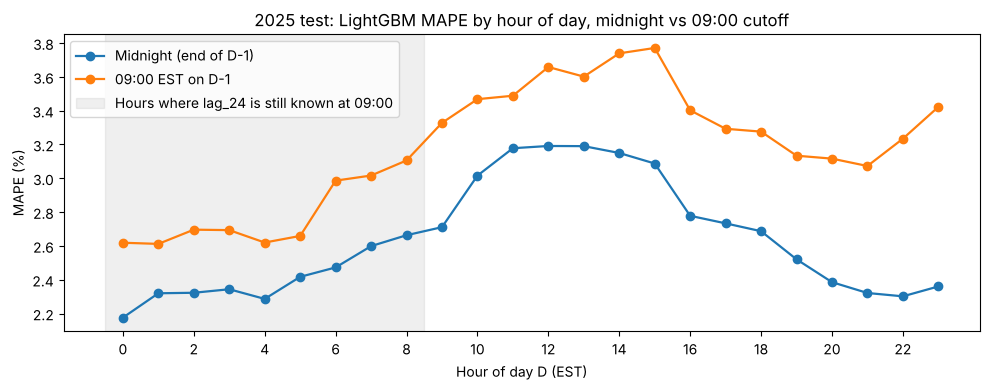

In [6]:
ape = pd.DataFrame({CUTOFFS[h]: (preds[h] - y).abs() / y * 100 for h in CUTOFFS})
by_hour = ape.groupby(ape.index.hour).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o", lw=1.6)
ax.axvspan(-0.5, 8.5, color="grey", alpha=0.12, label="Hours where lag_24 is still known at 09:00")
ax.set(title="2025 test: LightGBM MAPE by hour of day, midnight vs 09:00 cutoff",
       xlabel="Hour of day D (EST)", ylabel="MAPE (%)", xticks=range(0, 24, 2))
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig("figures/cutoff_mape_by_hour_2025.png", dpi=130)

blocks = {"00:00-08:59": range(0, 9), "09:00-15:59": range(9, 16), "16:00-23:59": range(16, 24)}
pd.DataFrame({k: by_hour.loc[list(v)].mean() for k, v in blocks.items()}).round(2)

**Reading the chart.** The 09:00 model is worse in every hour, but by different amounts. In the night and early morning, where it still has `lag_24`, MAPE rises by about 0.4 points (2.40% → 2.78%). Midday rises by about 0.5 points (3.07% → 3.58%) and stays the hardest block in absolute terms. The evening (16:00–23:59), which holds the winter and summer peaks, loses the most: about 0.7 points (2.51% → 3.24%). These are the hours furthest from the last demand the forecaster has seen.

## 5. What the model relies on now (feature importance)

**Gain importance** measures how much each feature reduces the training error, summed over all the trees, shown here as a percentage of the total. It shows what the model leans on, not cause and effect.

,Midnight (end of D-1),09:00 EST on D-1
lag_24,67.0,13.6
lag_168,10.8,30.3
lag_48,1.0,21.9
temp_c,4.8,8.1
hour,2.6,3.9
temp_day_mean,1.7,3.9
dow,3.2,3.1
cdd,1.0,3.1
prev2_day_max,0.0,2.6
prev_day_max,2.3,0.0


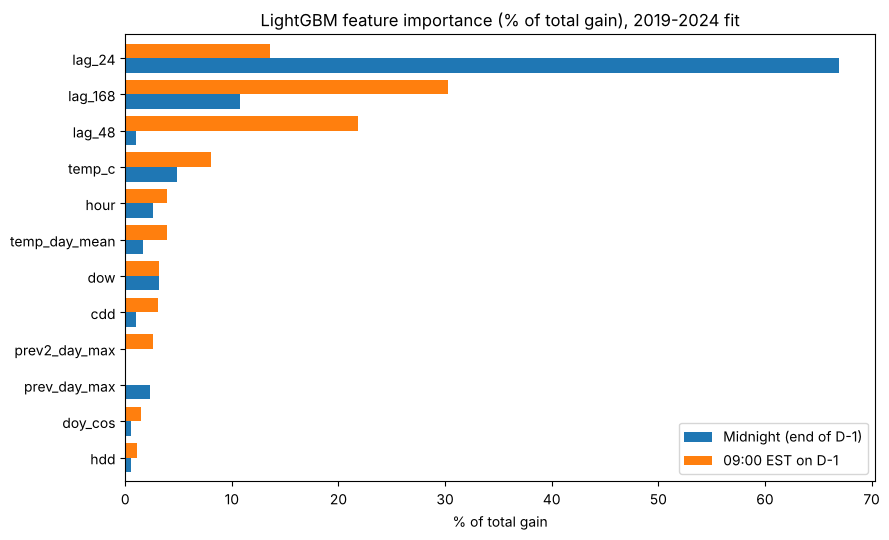

In [7]:
imp = {}
for h, m in models.items():
    g = pd.Series(m.booster_.feature_importance("gain"), index=get_features(h))
    imp[CUTOFFS[h]] = g / g.sum() * 100
imp = pd.DataFrame(imp).fillna(0)
top = imp.loc[imp.max(axis=1).sort_values(ascending=False).index[:12]]

fig, ax = plt.subplots(figsize=(9, 5.5))
top.iloc[::-1].plot(kind="barh", ax=ax, width=0.8)
ax.set(title="LightGBM feature importance (% of total gain), 2019-2024 fit", xlabel="% of total gain")
fig.tight_layout(); fig.savefig("figures/cutoff_feature_importance.png", dpi=130)
top.round(1)

**What changed.**

- At midnight, `lag_24` alone carries about two thirds of the gain (67%): the model is mostly "yesterday's same hour, adjusted".
- At 09:00 the weight is spread out. The one-week lag (`lag_168`, about 30%) and the two-day lag (`lag_48`, about 22%) take over, `lag_24` falls to about 14% (it only exists for the night and early morning), and temperature features matter more: with less recent demand information, the model has to rely more on the weather forecast.

In [8]:
print("Share of total gain at 09:00 for the new and replacement features:")
imp.loc[["last_known_demand", "morning_vs_last_week", "prev2_day_mean", "prev2_day_max"], CUTOFFS[9]].round(1)

Share of total gain at 09:00 for the new and replacement features:


last_known_demand       0.8
morning_vs_last_week    0.6
prev2_day_mean          0.5
prev2_day_max           2.6
Name: 09:00 EST on D-1, dtype: float64

The two new morning features carry only a small share of the gain (about 0.8% and 0.6%). The day-before-yesterday peak (`prev2_day_max`, 2.6%) is the most useful of the replacements. So the model mainly compensates through the two-day and one-week lags and the weather, not through the morning signal. A richer description of D-1 morning (for example its full hourly shape) could be worth testing.

## Takeaways

- **Honest headline:** with a realistic 09:00 EST day-ahead deadline, LightGBM forecasts 2025 hourly Ontario demand with **3.17% MAPE (541 MW MAE)** and **3.46% daily-peak MAPE**, against 2.63% / 2.76% for the optimistic midnight setup.
- **Still clearly useful:** the best forecast actually possible at 09:00 without a model (same hour two days ago) has 6.52% MAPE; the model halves the error.
- **The evening suffers most**, because those hours are the furthest from the last measured demand. That is also where the daily peaks are.
- **Next:** the model still uses observed weather for day D as a stand-in for a weather forecast, so 3.17% is still a little optimistic. Using archived weather forecasts (a later backlog item) would give the fully realistic number.